# 01 · Data Exploration and Cleaning

**Problem (Option C – The Smart Investor):** invest **$10,000** in **at most 5** of the ~500 S&P 500 companies so that the portfolio reaches a required expected return with the **minimum risk**.

In this assignment the data is **not used to train a model**. It *instantiates* the optimisation model:

| Model parameter | Derived from the data |
|---|---|
| $r_{ti}$ – return of stock $i$ in week $t$ | weekly close-to-close returns, 2013-02 → 2016-12 (estimation window) |
| $\mu_i$ – expected return | mean of $r_{ti}$ over the estimation window |
| $p_i$ – share price on the decision date | close on 2016-12-30 (for whole-share purchases) |
| out-of-sample validation | daily prices 2017-01 → 2018-02 |

**Dataset:** [S&P 500 stock data – Kaggle `camnugent/sandp500`](https://www.kaggle.com/datasets/camnugent/sandp500) (licence CC0: Public Domain). Daily open/high/low/close/volume for all companies in the S&P 500 index between 2013-02-08 and 2018-02-07.

**Contents**
1. Setup and parameters
2. Raw data and quality checks
3. Cleaning: incomplete histories and unadjusted corporate actions
4. Weekly returns and the train / test split
5. Exploratory analysis (risk vs return, fat tails, correlations, prices)
6. Export of the cleaned data used by notebook 02 (and by the heuristic)

## 1. Setup and parameters

In [1]:
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

pd.set_option("display.float_format", "{:.4f}".format)

All folders are relative to the repository root, so the notebook works on any machine.
The two thresholds define what counts as an *implausible* one-day move for an S&P 500 stock (explained in section 3).

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT / "data" / "raw" / "all_stocks_5yr.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "results" / "figures"

TRAIN_END = "2016-12-31"      # estimation window: 2013-02 .. 2016-12
TEST_START = "2017-01-01"     # out-of-sample window: 2017-01 .. 2018-02
TARGET_ANNUAL_RETURN = 0.20   # investor's required return (used here only for context)
BUDGET, MIN_WEIGHT = 10_000, 0.05
MAX_DAILY_DROP, MAX_DAILY_RISE = -0.30, 0.40   # outside this band = split / spin-off / bad tick

**Figure style.** One consistent look for every report figure: a colour-blind-safe palette (blue, orange, green), light grid, no top/right borders. `save()` writes each figure to `results/figures/` for the PDF report.

In [3]:
BLUE, ORANGE, GREEN, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "axes.titlelocation": "left", "axes.titleweight": "semibold", "axes.titlesize": 12,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.prop_cycle": mpl.cycler(color=[BLUE, ORANGE, GREEN]),
    "legend.frameon": False, "lines.linewidth": 2,
})

def save(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.png")

## 2. Raw data and quality checks
The CSV is committed in `data/raw/`. If it is missing, it is downloaded from Kaggle with `kagglehub`, which works for public datasets without an API token.

In [4]:
if not RAW_FILE.exists():
    import kagglehub
    src = kagglehub.dataset_download("camnugent/sandp500")
    RAW_FILE.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(Path(src) / "all_stocks_5yr.csv", RAW_FILE)

raw = pd.read_csv(RAW_FILE, parse_dates=["date"])
print(raw.shape)
raw.head()

(619040, 7)


,date,open,high,low,close,volume,Name
0,2013-02-08,15.0700,15.1200,14.6300,14.7500,8407500,AAL
1,2013-02-11,14.8900,15.0100,14.2600,14.4600,8882000,AAL
2,2013-02-12,14.4500,14.5100,14.1000,14.2700,8126000,AAL
3,2013-02-13,14.3000,14.9400,14.2500,14.6600,10259500,AAL
4,2013-02-14,14.9400,14.9600,13.1600,13.9900,31879900,AAL


In [5]:
pd.Series({
    "rows": len(raw),
    "tickers": raw["Name"].nunique(),
    "first date": raw["date"].min().date(),
    "last date": raw["date"].max().date(),
    "trading days": raw["date"].nunique(),
    "duplicate (date, ticker) rows": raw.duplicated(["date", "Name"]).sum(),
    "non-positive close prices": (raw["close"] <= 0).sum(),
}).to_frame("value")

,value
rows,619040
tickers,505
first date,2013-02-08
last date,2018-02-07
trading days,1259
"duplicate (date, ticker) rows",0
non-positive close prices,0


In [6]:
raw.isna().sum().to_frame("missing values")

,missing values
date,0
open,11
high,8
low,8
close,0
volume,0
Name,0


Only 11 `open` values are missing. The model uses **closing prices only**, and those are complete.

We reshape the long table (one row per day *and* ticker) into a wide **price matrix**: one row per trading day, one column per ticker.

In [7]:
prices_all = raw.pivot(index="date", columns="Name", values="close").sort_index()
prices_all.iloc[:5, :8]

Name,A,AAL,AAP,AAPL,ABBV,ABC,ABT,ACN
date,,,,,,,,
2013-02-08,45.0800,14.7500,78.9000,67.8542,36.2500,46.8900,34.4100,73.3100
2013-02-11,44.6000,14.4600,78.3900,68.5614,35.8500,46.7600,34.2600,73.0700
2013-02-12,44.6200,14.2700,78.6000,66.8428,35.4200,46.9600,34.3000,73.3700
2013-02-13,44.7500,14.6600,78.9700,66.7156,35.2700,46.6400,34.4600,73.5600
2013-02-14,44.5800,13.9900,78.8400,66.6556,36.5700,46.7700,34.7000,73.1300


## 3. Cleaning
### 3.1 Incomplete histories
Companies that joined the index (or listed) after Feb 2013 have fewer than 1,259 observations. The MAD risk model compares all stocks over the *same* weeks, so these are excluded.

In [8]:
complete = prices_all.notna().all()
short_history = sorted(prices_all.columns[~complete])
print(f"{len(short_history)} tickers with an incomplete history")
prices_all.notna().sum()[short_history].sort_values().head(10).to_frame("trading days available")

35 tickers with an incomplete history


,trading days available
Name,
APTV,44
DWDP,109
BHF,143
BHGE,152
DXC,215
HLT,276
EVHC,297
FTV,404
UA,464


### 3.2 Unadjusted stock splits and spin-offs ⚠️
The prices in this dataset are **not adjusted** for corporate actions. A 2-for-1 split appears as a −50% "return" that no investor actually suffered. Left in the data, these fake crashes would make the affected stocks look extremely risky and distort the optimiser.

We flag every daily move below −30% or above +40%:

In [9]:
prices = prices_all.loc[:, complete]
daily = prices.pct_change().iloc[1:]
jumps = daily[(daily < MAX_DAILY_DROP) | (daily > MAX_DAILY_RISE)].stack().reset_index()
jumps.columns = ["date", "ticker", "daily_return"]
jumps.sort_values("daily_return")

,date,ticker,daily_return
5,2015-07-02,NI,-0.6262
6,2015-07-20,EBAY,-0.5690
3,2014-08-07,DISCK,-0.5102
2,2014-08-07,DISCA,-0.5064
10,2016-05-19,LNT,-0.4945
4,2015-07-01,BAX,-0.4443
8,2016-02-08,WMB,-0.3481
12,2016-11-01,ARNC,-0.3412
7,2016-02-08,CHK,-0.3333
15,2017-11-21,SIG,-0.3039


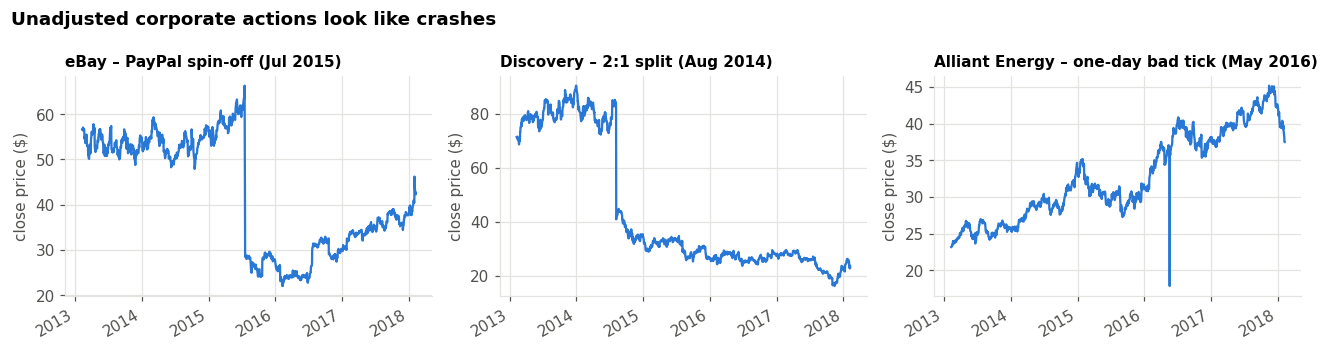

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (ticker, label) in zip(axes, [("EBAY", "eBay – PayPal spin-off (Jul 2015)"),
                                      ("DISCA", "Discovery – 2:1 split (Aug 2014)"),
                                      ("LNT", "Alliant Energy – one-day bad tick (May 2016)")]):
    prices_all[ticker].plot(ax=ax, color=BLUE, lw=1.5)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("close price ($)")
fig.suptitle("Unadjusted corporate actions look like crashes", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "01_unadjusted_corporate_actions")

These drops are share-count changes (splits, spin-offs) or data errors: the LNT price halves for one day and recovers the next. None of them is an economic loss. We cannot reliably reconstruct adjustment factors from this dataset alone, so the **13 affected tickers are removed** (2.8% of the universe). This is conservative and keeps the remaining return estimates trustworthy.

In [11]:
dropped_for_jumps = sorted(jumps["ticker"].unique())
prices = prices.drop(columns=dropped_for_jumps)

print(f"raw tickers                          : {prices_all.shape[1]}")
print(f"dropped – incomplete history         : {len(short_history)}")
print(f"dropped – split / spin-off / bad tick: {len(dropped_for_jumps)} {dropped_for_jumps}")
print(f"clean universe                       : {prices.shape[1]}")

# sanity checks: no gaps and no implausible moves remain
assert prices.notna().all().all()
remaining = prices.pct_change().iloc[1:]
assert remaining.min().min() >= MAX_DAILY_DROP and remaining.max().max() <= MAX_DAILY_RISE

raw tickers                          : 505
dropped – incomplete history         : 35
dropped – split / spin-off / bad tick: 13 ['AMD', 'ARNC', 'BAX', 'CHK', 'DISCA', 'DISCK', 'EBAY', 'LNT', 'NI', 'NWL', 'SIG', 'VRTX', 'WMB']
clean universe                       : 457


## 4. Weekly returns and the train / test split
**Why weekly returns?**
* Daily returns are noisy and affected by non-synchronous trading.
* Monthly returns would leave only ~47 observations for 457 stocks.
* Weekly data gives $T = 203$ scenarios in the estimation window. $T$ also sets the number of MAD constraints in the model ($2T$).

The return of week $t$ is $r_{ti} = P_{i,t} / P_{i,t-1} - 1$, using Friday closing prices.

In [12]:
weekly = prices.resample("W-FRI").last().pct_change().iloc[1:]
train, test = weekly.loc[:TRAIN_END], weekly.loc[TEST_START:]

print(f"weekly returns: {weekly.shape[0]} weeks x {weekly.shape[1]} stocks")
print(f"estimation (train): {train.index.min().date()} → {train.index.max().date()}  ({len(train)} weeks)")
print(f"out-of-sample (test): {test.index.min().date()} → {test.index.max().date()}  ({len(test)} weeks)")

weekly returns: 261 weeks x 457 stocks
estimation (train): 2013-02-15 → 2016-12-30  (203 weeks)
out-of-sample (test): 2017-01-06 → 2018-02-09  (58 weeks)


## 5. Exploratory analysis
### 5.1 Risk and return of each stock (estimation window)

In [13]:
stats = pd.DataFrame({
    "annual_return": train.mean() * 52,
    "annual_volatility": train.std() * np.sqrt(52),
    "weekly_MAD": (train - train.mean()).abs().mean(),
    "excess_kurtosis": train.kurt(),
})
stats["return_per_risk"] = stats["annual_return"] / stats["annual_volatility"]
stats.describe().T

,count,mean,std,min,25%,50%,75%,max
annual_return,457.0000,0.1356,0.1025,-0.1397,0.0717,0.1274,0.1862,0.6131
annual_volatility,457.0000,0.2349,0.0678,0.1288,0.1860,0.2233,0.2711,0.5850
weekly_MAD,457.0000,0.0241,0.0065,0.0141,0.0194,0.0231,0.0273,0.0548
excess_kurtosis,457.0000,2.5702,3.2562,-0.5051,0.8460,1.6582,2.8680,34.5279
return_per_risk,457.0000,0.6051,0.3964,-0.4487,0.3377,0.6258,0.8693,1.9046


91 of 457 stocks individually reach the 20% target


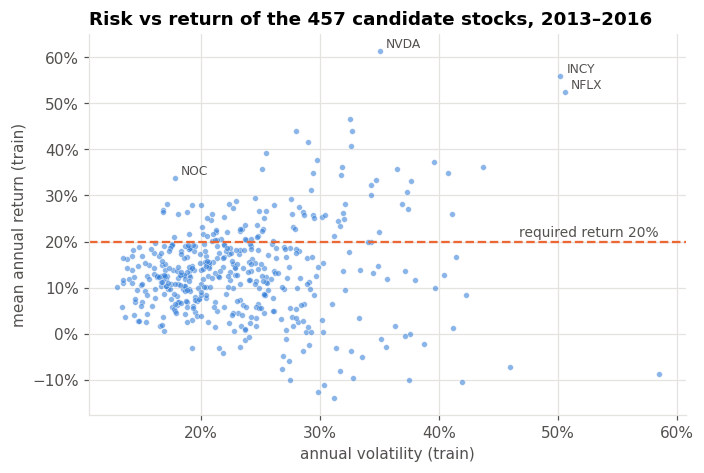

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(stats["annual_volatility"], stats["annual_return"], s=14, color=BLUE, alpha=0.55,
           edgecolor="white", linewidth=0.4)
ax.axhline(TARGET_ANNUAL_RETURN, color=ORANGE, lw=1.5, ls="--")
ax.text(stats["annual_volatility"].max(), TARGET_ANNUAL_RETURN + 0.01,
        f"required return {TARGET_ANNUAL_RETURN:.0%}", ha="right", color=MUTED, fontsize=9)
for t in stats["return_per_risk"].nlargest(2).index.union(stats["annual_return"].nlargest(3).index):
    ax.annotate(t, (stats.loc[t, "annual_volatility"], stats.loc[t, "annual_return"]),
                xytext=(4, 2), textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xlabel("annual volatility (train)")
ax.set_ylabel("mean annual return (train)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title(f"Risk vs return of the {len(stats)} candidate stocks, 2013–2016")
save(fig, "01_risk_return_universe")

n_above = (stats["annual_return"] >= TARGET_ANNUAL_RETURN).sum()
print(f"{n_above} of {len(stats)} stocks individually reach the {TARGET_ANNUAL_RETURN:.0%} target")

Only a minority of stocks reach the 20% target on their own, and those tend to be the more volatile ones. The optimiser has to combine high-return stocks with stocks that **move differently**, so that their deviations partly cancel. That interaction is what makes the selection hard.

### 5.2 Why Mean Absolute Deviation instead of variance?
Weekly stock returns are **fat-tailed** (positive excess kurtosis). Variance squares deviations, so a few extreme weeks dominate it. MAD weights deviations linearly, which makes it more robust to outliers. Its key advantage for this assignment is that it can be written with **linear** constraints, so the cardinality-constrained problem stays an MILP that PuLP can solve exactly (Konno & Yamazaki, 1991).

median excess kurtosis: 1.66; 96% of stocks are fat-tailed


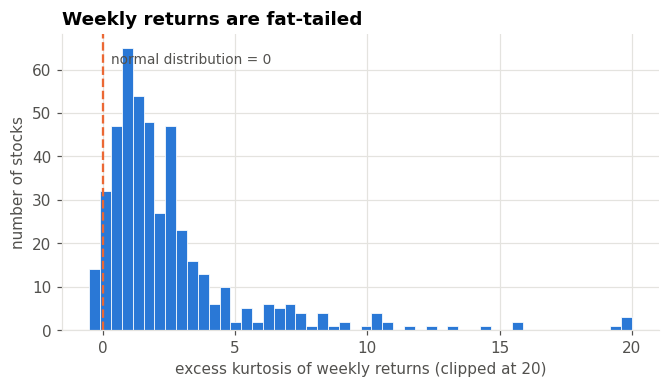

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(stats["excess_kurtosis"].clip(upper=20), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=ORANGE, lw=1.5, ls="--")
ax.text(0.3, ax.get_ylim()[1] * 0.9, "normal distribution = 0", color=MUTED, fontsize=9)
ax.set_xlabel("excess kurtosis of weekly returns (clipped at 20)")
ax.set_ylabel("number of stocks")
ax.set_title("Weekly returns are fat-tailed")
save(fig, "01_kurtosis")
print(f"median excess kurtosis: {stats['excess_kurtosis'].median():.2f}; "
      f"{(stats['excess_kurtosis'] > 0).mean():.0%} of stocks are fat-tailed")

### 5.3 Correlation structure

count   104196.0000
mean         0.2851
std          0.1416
min         -0.2666
25%          0.1902
50%          0.2803
75%          0.3745
max          0.9047
dtype: float64


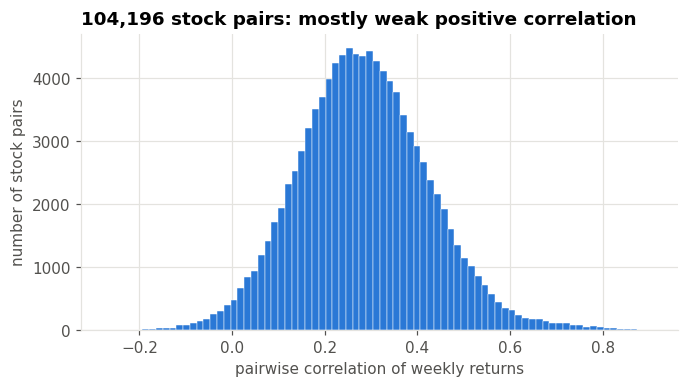

In [16]:
corr = train.corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(upper.describe())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(upper, bins=80, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xlabel("pairwise correlation of weekly returns")
ax.set_ylabel("number of stock pairs")
ax.set_title(f"{len(upper):,} stock pairs: mostly weak positive correlation")
save(fig, "01_correlations")

In [17]:
pd.concat([upper.nlargest(5), upper.nsmallest(5)]).to_frame("correlation")

correlation
Name Name             
CMS  DTE        0.9047
     XEL        0.9036
WEC  XEL        0.8986
CMS  WEC        0.8962
MET  PRU        0.8945
ED   SCHW      -0.2666
     LNC       -0.2540
     RF        -0.2482
     ETFC      -0.2408
CMA  ED        -0.2408

The most similar stocks are **utilities in the same regulated sector** (CMS, DTE, XEL, WEC, ρ ≈ 0.90): holding several of them adds almost no diversification. The few negative correlations pair a defensive utility (ED) with financial stocks (SCHW, LNC, RF, ETFC). These offsetting movements are exactly what a minimum-risk portfolio exploits.

### 5.4 Share prices on the decision date
The whole-share version of the model buys **whole shares** at the 2016-12-30 close. With $10,000 and a 5% minimum position ($500), very expensive stocks could be hard to fit:

In [18]:
p0 = prices.loc[:TRAIN_END].iloc[-1]
print(p0.describe())
print("\nmost expensive stocks:")
print(p0.nlargest(6).round(2).to_string())

count    457.0000
mean      92.6088
std      103.8131
min       11.6200
25%       46.9800
50%       71.9700
75%      105.6800
max     1466.0600
Name: 2016-12-30 00:00:00, dtype: float64

most expensive stocks:
Name
PCLN    1466.0600
GOOGL    792.4500
AZO      789.7900
AMZN     749.8700
MTD      418.5600
BLK      380.5400


Even the most expensive stock (PCLN ≈ $1,466) fits inside a $500–$4,000 position (5%–40% of $10,000). Rounding to whole shares therefore changes the weights only slightly.

## 6. Export the cleaned data
Notebook 02 (exact method) and the heuristic notebook read **exactly these files**, so both methods solve the identical problem instance:

| File | Content |
|---|---|
| `weekly_returns_train.csv` | 203 weeks × 457 stocks – builds the model |
| `weekly_returns_test.csv` | 58 weeks × 457 stocks – out-of-sample |
| `daily_close_clean.csv` | daily closes – decision-date prices and the backtest |

In [19]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train.to_csv(PROCESSED_DIR / "weekly_returns_train.csv")
test.to_csv(PROCESSED_DIR / "weekly_returns_test.csv")
prices.to_csv(PROCESSED_DIR / "daily_close_clean.csv")
sorted(p.name for p in PROCESSED_DIR.iterdir())

['daily_close_clean.csv',
 'weekly_returns_test.csv',
 'weekly_returns_train.csv']

## Summary
* 505 tickers → **457 clean stocks** (35 incomplete histories and 13 unadjusted corporate actions removed).
* **203 weekly scenarios** for estimation (2013–2016) and **58 weeks (≈13 months)** for out-of-sample validation (2017-01 → 2018-02).
* Returns are fat-tailed and mostly positively correlated, which supports a robust, linear risk measure (MAD).
* Search space: choosing up to 5 of 457 stocks gives $\sum_{k=1}^{5}\binom{457}{k} \approx 1.6\times10^{11}$ subsets, each with a continuous weight problem. Enumerating them is infeasible, so we need Branch & Bound (notebook 02).